---
## 0. Setup virtualenv

> **Esegui questi comandi nel terminale** (fuori da Jupyter) prima di avviare il notebook.

```bash
# Crea il virtualenv nella cartella del progetto
python3 -m venv .venv

# Attiva il virtualenv
source .venv/bin/activate          # macOS / Linux
# .venv\Scripts\activate           # Windows

# Installa il kernel Jupyter nel virtualenv
pip install ipykernel
python -m ipykernel install --user --name=quantizzazione --display-name "Python (quantizzazione)"

# Avvia Jupyter (solo se non usi vscode)
jupyter notebook
```

In [2]:
!pip install sentence-transformers scikit-learn matplotlib pandas seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Esempio 1 - Similarità Coseno tra frasi

In [3]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

model = SentenceTransformer("all-MiniLM-L6-v2")

sentences = [
    "Come preparare una pizza napoletana",
    "Ricetta tradizionale della pizza italiana",
    "Come sostituire la batteria di un'automobile",
    "Manutenzione del motore di una vettura"
]

embeddings = model.encode(sentences)

sim_matrix = cosine_similarity(embeddings)

df = pd.DataFrame(
    sim_matrix,
    index=sentences,
    columns=sentences
)

print(df.round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

                                              Come preparare una pizza napoletana  \
Come preparare una pizza napoletana                                         1.000   
Ricetta tradizionale della pizza italiana                                   0.622   
Come sostituire la batteria di un'automobile                                0.482   
Manutenzione del motore di una vettura                                      0.388   

                                              Ricetta tradizionale della pizza italiana  \
Come preparare una pizza napoletana                                               0.622   
Ricetta tradizionale della pizza italiana                                         1.000   
Come sostituire la batteria di un'automobile                                      0.314   
Manutenzione del motore di una vettura                                            0.320   

                                              Come sostituire la batteria di un'automobile  \
Come preparare una pizza

In [4]:
df

,Come preparare una pizza napoletana,Ricetta tradizionale della pizza italiana,Come sostituire la batteria di un'automobile,Manutenzione del motore di una vettura
Come preparare una pizza napoletana,1.000000,0.621983,0.482404,0.387811
Ricetta tradizionale della pizza italiana,0.621983,1.000000,0.313900,0.320380
Come sostituire la batteria di un'automobile,0.482404,0.313900,1.000000,0.617461
Manutenzione del motore di una vettura,0.387811,0.320380,0.617461,1.000000


# Esempio 2 - Visualizzazione nello spazio vettoriale

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

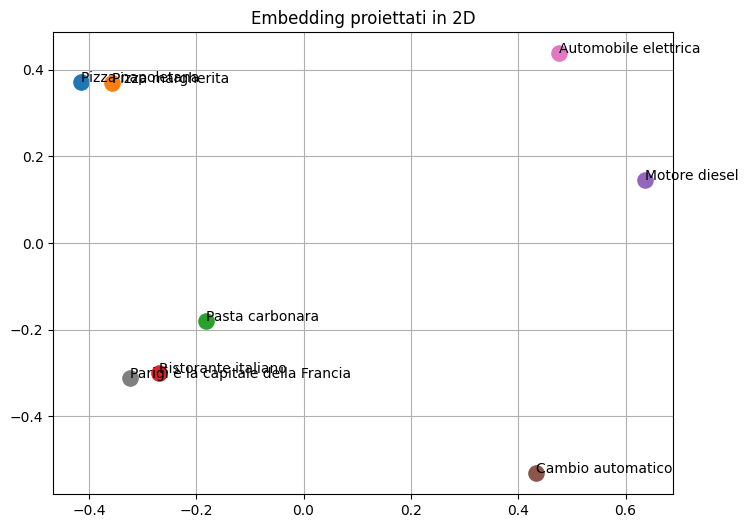

In [5]:
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

model = SentenceTransformer("all-MiniLM-L6-v2")

sentences = [
    "Pizza napoletana",
    "Pizza margherita",
    "Pasta carbonara",
    "Ristorante italiano",
    "Motore diesel",
    "Cambio automatico",
    "Automobile elettrica",
    "Parigi è la capitale della Francia",
    #"Quali sono le città francesi migliori?"
]

embeddings = model.encode(sentences)

pca = PCA(n_components=2)
coords = pca.fit_transform(embeddings)

plt.figure(figsize=(8,6))

for i, sentence in enumerate(sentences):
    plt.scatter(coords[i,0], coords[i,1], s=120)
    plt.text(
        coords[i,0],
        coords[i,1],
        sentence
    )

plt.title("Embedding proiettati in 2D")
plt.grid(True)
plt.show()


# Esempio 3 - Simulazione di un database vettoriale

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

documents = [
    "La pizza napoletana viene cotta nel forno a legna",
    "La carbonara si prepara con guanciale e pecorino",
    "Le auto elettriche utilizzano batterie agli ioni di litio",
    "Il motore diesel garantisce elevata coppia"
]

query = "Come si cucina una pizza?"

model = SentenceTransformer("all-MiniLM-L6-v2")

doc_embeddings = model.encode(documents)
query_embedding = model.encode([query])

scores = cosine_similarity(
    query_embedding,
    doc_embeddings
)[0]

ranking = np.argsort(scores)[::-1]

print(f"\nQUERY: {query}\n")

for i in ranking:
    print(
        f"Score={scores[i]:.3f} -> {documents[i]}"
    )

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


QUERY: Come si cucina una pizza?

Score=0.632 -> La pizza napoletana viene cotta nel forno a legna
Score=0.478 -> La carbonara si prepara con guanciale e pecorino
Score=0.387 -> Le auto elettriche utilizzano batterie agli ioni di litio
Score=0.303 -> Il motore diesel garantisce elevata coppia


# Esempio 4 - Heatmap delle similarità

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt

sentences = [
    "Pizza napoletana",
    "Pizza margherita",
    "Pasta carbonara",
    "Automobile elettrica",
    "Motore diesel"
]

model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(sentences)

sim = cosine_similarity(embeddings)

plt.figure(figsize=(8,6))

sns.heatmap(
    sim,
    annot=True,
    cmap="YlGnBu",
    xticklabels=sentences,
    yticklabels=sentences
)

plt.title("Matrice di Similarità Coseno")
plt.show()

# Esempio 5 - Il Chunking

Se divido troppo il testo rischiamo di perdere contesto o miglioriamo la ricerca?

In [ ]:
text = """La pizza napoletana è un prodotto tradizionale italiano.
Viene cotta ad alte temperature.
L'impasto richiede una lunga lievitazione.
L'automobile moderna integra numerosi sistemi elettronici."""

chunk_sizes = [30, 50, 100]

for chunk_size in chunk_sizes:
    print(f'CHUNK SIZE = {chunk_size}')
    chunks = [
        text[i:i+chunk_size]
        for i in range(0, len(text), chunk_size)
    ]

    for i, chunk in enumerate(chunks):
        print(f"CHUNK {i+1}")
        print(chunk)

CHUNK SIZE = 30
CHUNK 1
La pizza napoletana è un prodo
CHUNK 2
tto tradizionale italiano.
Vie
CHUNK 3
ne cotta ad alte temperature.

CHUNK 4
L'impasto richiede una lunga l
CHUNK 5
ievitazione.
L'automobile mode
CHUNK 6
rna integra numerosi sistemi e
CHUNK 7
lettronici.

CHUNK SIZE = 50
CHUNK 1
La pizza napoletana è un prodotto tradizionale ita
CHUNK 2
liano.
Viene cotta ad alte temperature.
L'impasto 
CHUNK 3
richiede una lunga lievitazione.
L'automobile mode
CHUNK 4
rna integra numerosi sistemi elettronici.

CHUNK SIZE = 100
CHUNK 1
La pizza napoletana è un prodotto tradizionale italiano.
Viene cotta ad alte temperature.
L'impasto 
CHUNK 2
richiede una lunga lievitazione.
L'automobile moderna integra numerosi sistemi elettronici.



Chuck dinamico per frasi

In [ ]:
text = """La pizza napoletana è un prodotto tradizionale italiano.
Viene cotta ad alte temperature.
L'impasto richiede una lunga lievitazione.
L'automobile moderna integra numerosi sistemi elettronici."""


chunks = text.split('\n')

for i, chunk in enumerate(chunks):
    print(f"CHUNK {i+1}")
    print(chunk)

CHUNK 1
La pizza napoletana è un prodotto tradizionale italiano.
CHUNK 2
Viene cotta ad alte temperature.
CHUNK 3
L'impasto richiede una lunga lievitazione.
CHUNK 4
L'automobile moderna integra numerosi sistemi elettronici.


Chunking dinamico con sliding window

In [ ]:
from typing import List


def chunk_words_sliding_window(
    text: str,
    chunk_size: int = 20,
    overlap: int = 5
) -> List[str]:

    words = text.split()

    if overlap >= chunk_size:
        raise ValueError("overlap deve essere minore di chunk_size")

    step = chunk_size - overlap
    chunks = []

    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]

        if not chunk_words:
            break

        chunks.append(" ".join(chunk_words))

        if start + chunk_size >= len(words):
            break

    return chunks


text = """L'Inter è una delle squadre più titolate del calcio italiano.
Fondata nel 1908, ha conquistato numerosi campionati.
Nel 2010 ha ottenuto il Triplete vincendo Serie A,
Coppa Italia e Champions League."""

chunks = chunk_words_sliding_window(
    text,
    chunk_size=10,
    overlap=5
)

for i, chunk in enumerate(chunks, 1):
    print(f"\nChunk {i}:")
    print(chunk)



Chunk 1:
L'Inter è una delle squadre più titolate del calcio italiano.

Chunk 2:
più titolate del calcio italiano. Fondata nel 1908, ha conquistato

Chunk 3:
Fondata nel 1908, ha conquistato numerosi campionati. Nel 2010 ha

Chunk 4:
numerosi campionati. Nel 2010 ha ottenuto il Triplete vincendo Serie

Chunk 5:
ottenuto il Triplete vincendo Serie A, Coppa Italia e Champions

Chunk 6:
A, Coppa Italia e Champions League.
